# Banknote Authentication

Genuine and forged banknotes were photographed, and each note image was summarised by four statistics of its wavelet transform — **variance, skewness, curtosis and entropy**. Forged notes distort the printed patterns just enough to shift these numbers. Classify each note as genuine (0) or forged (1) from the four statistics alone.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# UCI serves this dataset as a ready CSV at the dataset's data_url
df = pd.read_csv(io.BytesIO(download('https://archive.ics.uci.edu/static/public/267/data.csv')))
print(df.shape)
df.head(3)

(1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.6216,8.6661,-2.8073,-0.44699,0
1,4.5459,8.1674,-2.4586,-1.46210,0
2,3.8660,-2.6383,1.9242,0.10645,0


In [2]:
X = df.drop(columns=['class']); y = df['class']  # 0 = genuine, 1 = forged
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.9942
Logistic Regression accuracy: 0.9738
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       191
           1       0.99      1.00      0.99       152

    accuracy                           0.99       343
   macro avg       0.99      0.99      0.99       343
weighted avg       0.99      0.99      0.99       343



variance    0.555975
skewness    0.241091
curtosis    0.148317
entropy     0.054617
dtype: float64


<Axes: title={'center': 'Which wavelet statistics expose a forgery?'}>

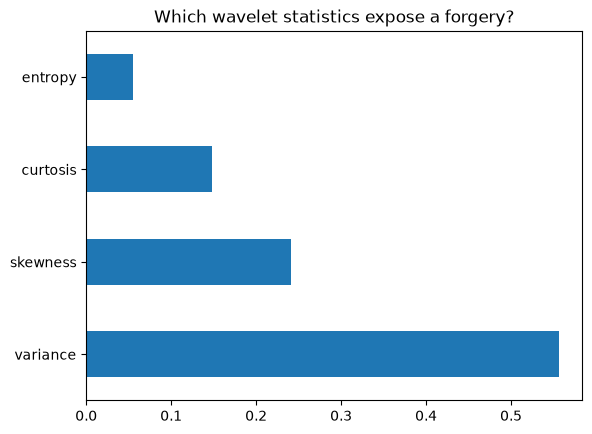

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which wavelet statistics expose a forgery?')